# Day 32 — Getting Data Into Shape
### Module 3 · Machine Learning · Topics 3.3 + 3.4

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

## Read this first

Last time we turned **words** into numbers. Today we fix the **numbers themselves**.

**You do not need anything from earlier classes.** Every idea is explained here when it
first appears, and every cell is short.

| § | Section | The question it answers |
|---|---|---|
| 1 | Why scaling matters | Why does a bigger column drown out a smaller one? |
| 2 | The three scalers | How do we fix it, and which one do I pick? |
| 3 | Making new features | Can I give the model columns it could never work out itself? |
| 4 | Too many features | Is more columns always better? (No.) |
| 5 | Put it together | In what **order** do I do all of this? |

Section 5 is the one to write down. **Doing these steps in the wrong order is the most
common mistake in machine learning**, and it is the one that quietly inflates your score.

---
## Setting up

One cell. Run it and forget about it.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

import warnings
warnings.simplefilter("ignore")

plt.rcParams["figure.figsize"] = (8, 3.4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Ready. Move on to Part 1.")

Ready. Move on to Part 1.


---
# Part 1 · Why scaling matters

## 1.1 · The problem, in one table

Here are two columns from the same list of phones.

In [19]:
phones = pd.DataFrame({
    "ram_gb": [4, 6, 8, 12, 16],
    "price":  [9000, 15000, 24000, 42000, 80000],
})
phones

,ram_gb,price
0,4,9000
1,6,15000
2,8,24000
3,12,42000
4,16,80000


In [20]:
print("RAM   goes from", phones.ram_gb.min(), "to", phones.ram_gb.max())
print("price goes from", f"{phones.price.min():,}", "to", f"{phones.price.max():,}")
print()
print("The price column is about", round(phones.price.max() / phones.ram_gb.max()),
      "times bigger than the RAM column.")

RAM   goes from 4 to 16
price goes from 9,000 to 80,000

The price column is about 5000 times bigger than the RAM column.


Nothing is wrong with that data. Both columns are correct.

But a lot of models work by asking **"which other rows look like this one?"** To answer
that, they add up how far apart the columns are — and a column measured in tens of
thousands completely drowns out one that stops at 16.

**The price column is not more important. It is just bigger.**

## 1.2 · Watch a model pick the wrong phone

You are holding a phone with **8 GB of RAM** costing **₹30,000**. Which of these two is
most like it?

In [21]:
mine    = np.array([8.,  30000])    # the phone in my hand
phone_A = np.array([8.,  32000])    # same RAM, Rs2,000 dearer
phone_B = np.array([16., 30500])    # DOUBLE the RAM, Rs500 dearer

def distance(p, q):
    return np.sqrt(((p - q) ** 2).sum())

print("raw distance to A (same RAM, +Rs2,000) :", round(distance(mine, phone_A), 1))
print("raw distance to B (DOUBLE RAM, +Rs500) :", round(distance(mine, phone_B), 1))

raw distance to A (same RAM, +Rs2,000) : 2000.0
raw distance to B (DOUBLE RAM, +Rs500) : 500.1


### The computer says B is more similar

But phone B has **twice the RAM**. It is a completely different phone. The only reason it
looks closer is that ₹500 is a smaller number than ₹2,000 — and the RAM difference of 8 GB
counted for almost nothing next to it.

### Now let us put both columns on a fair footing

In [22]:
# the spread of a real market of 400 phones
rng = np.random.default_rng(3201)
market = np.column_stack([
    rng.choice([4, 6, 8, 12, 16], 400).astype(float),
    rng.normal(30000, 9000, 400).clip(8000, 80000),
])
print(f"in the real market:  RAM varies by about {market[:,0].std():.1f} GB")
print(f"                     price varies by about Rs{market[:,1].std():,.0f}")

scaler = StandardScaler().fit(market)

in the real market:  RAM varies by about 4.4 GB
                     price varies by about Rs8,816


In [23]:
m_s, A_s, B_s = scaler.transform([mine, phone_A, phone_B])

print("scaled distance to A :", round(distance(m_s, A_s), 3))
print("scaled distance to B :", round(distance(m_s, B_s), 3))
print()
print("Now it picks A - which was the right answer all along.")

scaled distance to A : 0.227
scaled distance to B : 1.831

Now it picks A - which was the right answer all along.


### What just happened

Scaling asked a better question. Instead of *"how many units apart are they?"* it asks
**"how unusual is this difference, compared with the normal spread of that column?"**

- ₹2,000 is a **small** difference in a market where prices vary by ₹9,000.
- 8 GB is a **huge** difference in a market where RAM varies by about 4 GB.

## 1.3 · So who actually needs scaling?

Let us measure it on 500 phones, with three different models.

In [24]:
rng = np.random.default_rng(321)
n = 500
ram   = rng.choice([4, 6, 8, 12, 16], n).astype(float)
price = rng.normal(30000, 9000, n).clip(8000, 80000)
quality = 0.18*ram + 0.00004*price + rng.normal(0, 0.35, n)    # what we want to predict

X = np.column_stack([ram, price])
X_train, X_hidden, y_train, y_hidden = train_test_split(X, quality, test_size=.3, random_state=0)

sc = StandardScaler().fit(X_train)                 # learn from the training rows only
X_train_s, X_hidden_s = sc.transform(X_train), sc.transform(X_hidden)

print(f"{'model':<24}{'no scaling':>12}{'with scaling':>14}{'change':>10}")
print("-" * 60)
for name, model in [("k-nearest neighbours", KNeighborsRegressor(7)),
                    ("linear regression",    LinearRegression()),
                    ("decision tree",        DecisionTreeRegressor(max_depth=6, random_state=0))]:
    raw = model.fit(X_train, y_train).score(X_hidden, y_hidden)
    scl = model.fit(X_train_s, y_train).score(X_hidden_s, y_hidden)
    print(f"{name:<24}{raw:>12.3f}{scl:>14.3f}{scl-raw:>+10.3f}")

model                     no scaling  with scaling    change
------------------------------------------------------------
k-nearest neighbours           0.056         0.872    +0.816
linear regression              0.886         0.886    +0.000
decision tree                  0.825         0.825    +0.000


### Three completely different answers

**k-nearest neighbours: 0.056 → 0.872.** Almost useless, then almost perfect. It works
purely by measuring distance, so the price column was drowning out the RAM column
entirely.

**Linear regression: no change at all.** It can simply learn a tiny weight for price and a
large one for RAM. The scale does not stop it. *(We still scale it in practice — for speed
and for readable weights — but not for a better score.)*

**Decision tree: no change at all, ever.** A tree asks questions like *"is RAM above 8?"*
Making the numbers bigger or smaller does not change the order they come in, so the same
questions are available and the same tree gets built.

| Needs scaling? | Models |
|---|---|
| **Yes, badly** | k-nearest neighbours, SVM, k-means, PCA, neural networks |
| **No, never** | decision trees, random forests |
| **Yes, but not for accuracy** | linear and logistic regression |

## 1.4 · And what it does to the picture

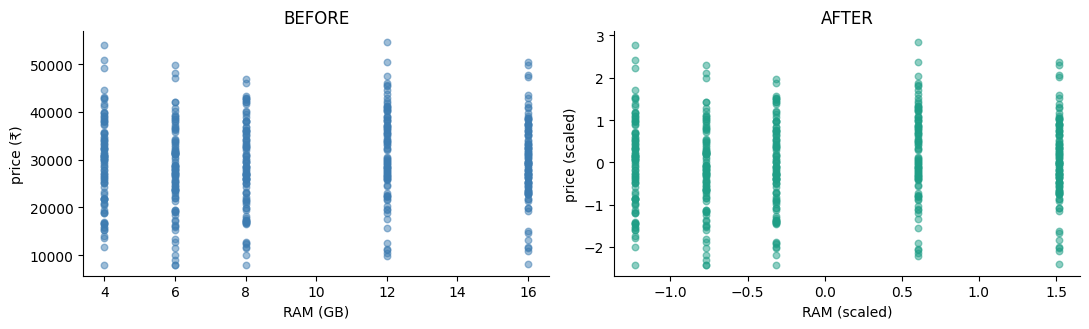

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].scatter(ram, price, s=22, alpha=.5, color="#3E7CB1")
axes[0].set_xlabel("RAM (GB)"); axes[0].set_ylabel("price (₹)")
axes[0].set_title("BEFORE")

Z = StandardScaler().fit_transform(np.column_stack([ram, price]))
axes[1].scatter(Z[:, 0], Z[:, 1], s=22, alpha=.5, color="#1F9E86")
axes[1].set_xlabel("RAM (scaled)"); axes[1].set_ylabel("price (scaled)")
axes[1].set_title("AFTER")

plt.tight_layout(); plt.show()

**It is exactly the same cloud of points.** Only the numbers on the axes moved.

Scaling never adds information and never throws any away. It just makes every column speak
at the same volume.

---
# Part 2 · The three scalers

There are three common ways to do this. Let us run all three on six monthly salaries —
five members of staff and one CEO.

In [26]:
salary = np.array([30., 35, 40, 45, 50, 400])      # thousands of rupees per month

print("mean   :", salary.mean())
print("sd     :", round(salary.std(), 2))
print("min    :", salary.min(), "    max:", salary.max())
print("median :", np.median(salary))
q1, q3 = np.percentile(salary, [25, 75])
print("IQR    :", q3 - q1, "  (the middle half of the data)")

mean   : 100.0
sd     : 134.32
min    : 30.0     max: 400.0
median : 42.5
IQR    : 12.5   (the middle half of the data)


## 2.1 · All three, side by side

| Scaler | The formula | The question it answers |
|---|---|---|
| **Standard** | (x − mean) ÷ sd | "How many standard deviations from average is this?" |
| **Min-max** | (x − min) ÷ range | "Where does this sit between smallest and largest?" |
| **Robust** | (x − median) ÷ IQR | "How far from the *typical* value is this?" |

In [27]:
col = salary.reshape(-1, 1)      # sklearn wants a table, so one column

results = pd.DataFrame({
    "salary":   salary,
    "standard": StandardScaler().fit_transform(col).ravel().round(2),
    "min-max":  MinMaxScaler().fit_transform(col).ravel().round(2),
    "robust":   RobustScaler().fit_transform(col).ravel().round(2),
})
results

,salary,standard,min-max,robust
0,30.0,-0.52,0.00,-1.0
1,35.0,-0.48,0.01,-0.6
2,40.0,-0.45,0.03,-0.2
3,45.0,-0.41,0.04,0.2
4,50.0,-0.37,0.05,0.6
5,400.0,2.23,1.00,28.6


### Read the last row across

That is the CEO, on ₹400k.

- **Standard** puts the CEO at +2.23
- **Min-max** puts the CEO at exactly 1.00 (it is the maximum, by definition)
- **Robust** puts the CEO at +28.60 — *"you are twenty-eight IQRs from typical"*

Robust is the only one that says what is actually true: **this person is extraordinary**.

## 2.2 · ⚠️ Now look at what happened to everybody else

In [28]:
for name in ["standard", "min-max", "robust"]:
    five = results[name][:5]                     # the five ordinary staff
    print(f"{name:<10}: the 5 staff are spread over {five.max() - five.min():.2f}")

standard  : the 5 staff are spread over 0.15
min-max   : the 5 staff are spread over 0.05
robust    : the 5 staff are spread over 1.60


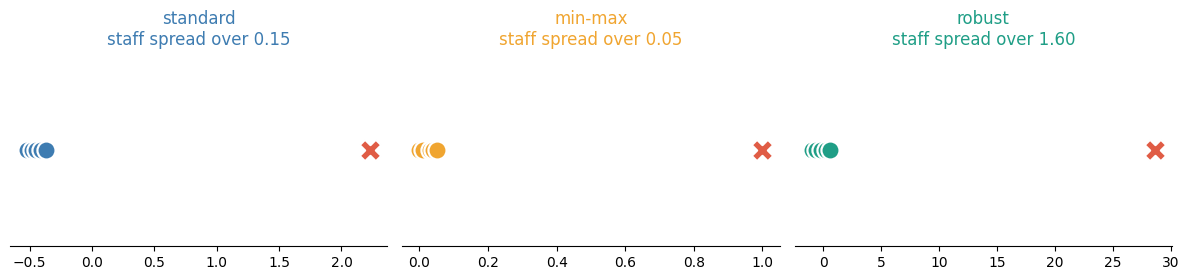

The X is the CEO. The five dots are everybody else.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))

for ax, name, colr in zip(axes, ["standard", "min-max", "robust"],
                          ["#3E7CB1", "#F0A530", "#1F9E86"]):
    vals = results[name].values
    ax.scatter(vals[:5], [0]*5, s=170, color=colr, zorder=3, edgecolor="white", lw=1.6)
    ax.scatter(vals[5:], [0],   s=240, color="#E05C45", marker="X", zorder=4,
               edgecolor="white", lw=1.6)
    ax.set_title(f"{name}\nstaff spread over {vals[:5].max()-vals[:5].min():.2f}",
                 fontsize=12, color=colr)
    ax.set_yticks([]); ax.spines["left"].set_visible(False)

plt.tight_layout(); plt.show()
print("The X is the CEO. The five dots are everybody else.")

### Min-max is the fragile one

Its whole output is defined by **two numbers** — the smallest and the largest. And those
are exactly the two values most likely to be a typo or a freak case.

Here, one CEO squeezed all five ordinary salaries into a span of **0.05**. After scaling,
a ₹30k salary and a ₹50k salary are almost the same number.

### So which should I use?

| Scaler | Use it when |
|---|---|
| **StandardScaler** | **Your default.** Nine times out of ten, use this. |
| **MinMaxScaler** | You specifically need every value between 0 and 1. |
| **RobustScaler** | Your data has real outliers you cannot just delete. |

```python
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
```

If you cannot decide, use `StandardScaler`. It is almost never the wrong answer.

---
# Part 3 · Making new features

Sometimes the column the model needs is **not in your table** — but you can build it out
of the ones that are.

## 3.1 · A ratio the model could never invent

We want to predict the **tip** on a food order. We know the **total bill** and the
**number of items**.

In [30]:
rng = np.random.default_rng(322)
N = 800

items = np.exp(rng.uniform(0, 4.1, N)).round().clip(1, None)    # 1 to about 60 items
per_item = rng.normal(180, 85, N).clip(60, None)                # price per item
bill = items * per_item

# the truth: people tip based on how FANCY the food is, not how much they ordered
tip = 0.5 + 0.055 * per_item + rng.normal(0, 1.6, N)

orders = pd.DataFrame({"bill": bill.round(0), "items": items, "tip": tip.round(2)})
orders.head()

,bill,items,tip
0,590.0,4.0,7.42
1,1996.0,7.0,14.04
2,577.0,3.0,9.34
3,554.0,3.0,15.62
4,2127.0,11.0,11.47


In [31]:
def score_with(columns, data):
    """Fit a model on these columns and report the score on hidden rows."""
    X = data[columns]
    X_train, X_hidden, y_train, y_hidden = train_test_split(
        X, data["tip"], test_size=0.3, random_state=0)
    return LinearRegression().fit(X_train, y_train).score(X_hidden, y_hidden)

print(f"using the bill and the item count : {score_with(['bill', 'items'], orders):.3f}")

using the bill and the item count : 0.390


0.390. Not great.

The model has both numbers. Why can it not work out the price per item itself?

**Because a model can only ADD its columns together and MULTIPLY them by weights.** It can
never DIVIDE one column by another. So `bill ÷ items` is mathematically out of its reach —
unless we hand it over.

In [32]:
orders["per_item"] = orders["bill"] / orders["items"]

print(f"using the bill and the item count : {score_with(['bill', 'items'], orders):.3f}")
print(f"after adding bill / items         : {score_with(['bill', 'items', 'per_item'], orders):.3f}")

using the bill and the item count : 0.390
after adding bill / items         : 0.883


### 0.390 → 0.883

**No new measurement was taken.** Nobody collected extra data. We simply rearranged two
columns the model already had, into a shape it could actually use.

This is what people mean by **feature engineering**, and it is often worth more than
switching to a fancier model.

## 3.2 · A date is never a feature

Now a different dataset: 900 food orders, and how many minutes each delivery took.

In [33]:
rng = np.random.default_rng(323)
D = 900

ordered_at = pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 24*120, D), "h")
hour = ordered_at.hour

# deliveries are slow at dinner time, because every restaurant is busy
is_dinner = ((hour >= 19) & (hour <= 22)).astype(float)
minutes = 22 + 14*is_dinner + rng.normal(0, 4, D)

deliveries = pd.DataFrame({"ordered_at": ordered_at, "minutes": minutes.round(1)})
deliveries.head()

,ordered_at,minutes
0,2025-04-09 21:00:00,38.4
1,2025-02-03 10:00:00,23.8
2,2025-03-24 21:00:00,39.3
3,2025-04-11 05:00:00,24.8
4,2025-01-20 20:00:00,30.7


In [34]:
# try the timestamp as a raw number: seconds since the 1st of January
raw_number = (deliveries.ordered_at - pd.Timestamp("2025-01-01")).dt.total_seconds()

deliveries["raw_number"] = raw_number
deliveries["hour"]       = deliveries.ordered_at.dt.hour
deliveries["is_dinner"]  = ((deliveries.hour >= 19) & (deliveries.hour <= 22)).astype(int)

def score_delivery(col):
    X = deliveries[[col]]
    a, b, c, d = train_test_split(X, deliveries["minutes"], test_size=.3, random_state=0)
    return LinearRegression().fit(a, c).score(b, d)

for col in ["raw_number", "hour", "is_dinner"]:
    print(f"  {col:<12}: {score_delivery(col):+.3f}")

  raw_number  : -0.007
  hour        : +0.232
  is_dinner   : +0.637


### Three ways to use the same column

| What we gave the model | Score |
|---|---|
| the raw timestamp | **−0.007** — completely useless |
| the hour of the day | **+0.232** — starting to work |
| "is it between 7pm and 10pm?" | **+0.637** — now it works properly |

**A raw timestamp is just a big counter.** It goes up forever and tells the model nothing.

Pulling out the **hour** helps, because the hour repeats and has meaning. But the hour
treats 1am and 2am as "close together" and 11pm and midnight as "far apart", which is not
how a clock works.

Asking the **real question** — *is this dinner time?* — works best of all, because that is
the thing that actually makes deliveries slow.

## 3.3 · Four recipes you will use again and again

| Recipe | Examples |
|---|---|
| **Divide one column by another** | bill ÷ items = price per item · spend ÷ days = spend per day |
| **Pull a date apart** | the hour · the weekday · is it a weekend? · days since signup |
| **Add things up** | maths + science = total marks · all room sizes = floor area |
| **Make a yes/no flag** | is the phone less than a year old? · is it raining? |

### ⚠️ One rule

**Add features one at a time and check the score each time.** A feature that does not move
the score is a feature you should delete — it only adds noise.

---
# Part 4 · Too many features

More columns *feels* like more information. Past a point it is the opposite.

## 4.1 · Watch a good model fall apart

In [35]:
rng = np.random.default_rng(324)
n = 250

real = rng.normal(0, 1, (n, 3))                                    # 3 columns that matter
target = 5 + 2*real[:,0] - 1.5*real[:,1] + 0.8*real[:,2] + rng.normal(0, 1.0, n)

print(f"{'junk columns added':>20}{'studied rows':>15}{'NEW rows':>12}")
print("-" * 48)
studied_scores, hidden_scores, counts = [], [], []
for k in [0, 5, 20, 60, 150]:
    X = np.column_stack([real, rng.normal(0, 1, (n, k))]) if k else real
    a, b, c, d = train_test_split(X, target, test_size=.3, random_state=0)
    m = LinearRegression().fit(a, c)
    print(f"{k:>20}{m.score(a, c):>15.3f}{m.score(b, d):>12.3f}")
    counts.append(k); studied_scores.append(m.score(a, c)); hidden_scores.append(m.score(b, d))

  junk columns added   studied rows    NEW rows
------------------------------------------------
                   0          0.885       0.854
                   5          0.892       0.833
                  20          0.899       0.854
                  60          0.925       0.761
                 150          0.981      -0.454


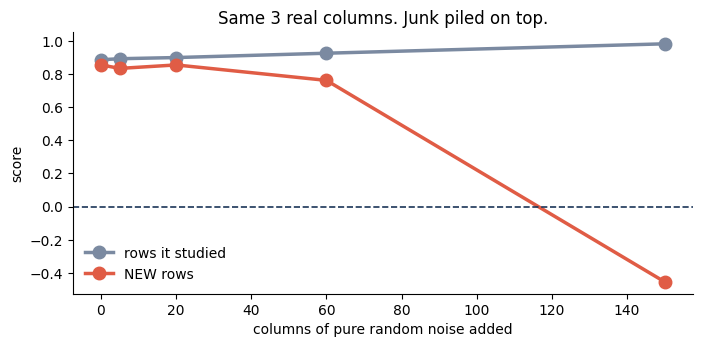

In [36]:
plt.plot(counts, studied_scores, "-o", lw=2.5, ms=9, color="#7B8AA1", label="rows it studied")
plt.plot(counts, hidden_scores,  "-o", lw=2.5, ms=9, color="#E05C45", label="NEW rows")
plt.axhline(0, color="#1B3558", lw=1.2, ls="--")
plt.xlabel("columns of pure random noise added"); plt.ylabel("score")
plt.legend(frameon=False)
plt.title("Same 3 real columns. Junk piled on top.")
plt.show()

### The two lines go in opposite directions

Every one of those extra columns is **pure random noise**, generated on the spot. They
cannot possibly help.

But the grey line keeps climbing — the model looks better and better on the rows it
studied. Meanwhile the red line falls off a cliff, ending at **−0.454**, which is **worse
than just guessing the average** for every row.

**Why?** With 250 rows and 153 columns, the model has nearly one adjustable knob per row.
It stops finding patterns and starts remembering rows.

## 4.2 · So keep only the columns that help

The simplest method: score each column on its own, and keep the best few.

In [37]:
from sklearn.feature_selection import SelectKBest, f_regression

X = np.column_stack([real, rng.normal(0, 1, (n, 150))])          # 3 real + 150 junk
a, b, c, d = train_test_split(X, target, test_size=.3, random_state=0)

picker = SelectKBest(f_regression, k=3).fit(a, c)
chosen = np.where(picker.get_support())[0]
print("columns it chose to keep:", chosen, " (the real ones are 0, 1, 2)")

m = LinearRegression().fit(picker.transform(a), c)
print(f"score on NEW rows after picking: {m.score(picker.transform(b), d):+.3f}")
print("                    (it was -0.454 with all 153 columns)")

columns it chose to keep: [0 1 2]  (the real ones are 0, 1, 2)
score on NEW rows after picking: +0.854
                    (it was -0.454 with all 153 columns)


It found the three real columns and threw away the other 150. The score went from **−0.454
back up to a healthy number.**

## 4.3 · ⚠️ But pick them at the wrong moment and you fool yourself

This is the most important warning of the whole day.

We are going to make a dataset where **there is genuinely nothing to find**: 100 rows,
3,000 columns of random numbers, and a target that is also random. The honest answer is
zero.

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

rng = np.random.default_rng(325)
X_noise = rng.normal(0, 1, (100, 3000))
y_noise = rng.normal(0, 1, 100)           # nothing on earth predicts this

print("3,000 columns of random numbers, and a random target.")
print("Nothing can predict it. The honest score is 0.")

3,000 columns of random numbers, and a random target.
Nothing can predict it. The honest score is 0.


In [39]:
# THE WRONG ORDER - pick the best columns using ALL the rows, then test
chosen = SelectKBest(f_regression, k=10).fit(X_noise, y_noise).get_support()
wrong = cross_val_score(Ridge(), X_noise[:, chosen], y_noise, cv=5).mean()

# THE RIGHT ORDER - pick the columns inside each split, using training rows only
pipe = Pipeline([("pick", SelectKBest(f_regression, k=10)), ("model", Ridge())])
right = cross_val_score(pipe, X_noise, y_noise, cv=5).mean()

print(f"picked the columns BEFORE splitting : {wrong:+.3f}   <-- looks like a real finding")
print(f"picked them INSIDE each split       : {right:+.3f}   <-- the truth")

picked the columns BEFORE splitting : +0.421   <-- looks like a real finding
picked them INSIDE each split       : -0.280   <-- the truth


### +0.42 out of absolutely nothing

Think about what happened. With 3,000 random columns and 100 rows, **some of them will
match the target by pure chance.** The picker hunted through all 3,000 and found the ten
luckiest ones — and it was allowed to look at the test rows while doing it.

By the time we tested, the test rows had already helped choose the columns. They were
never really hidden.

**The lesson:** hide the rows **first**. Then everything after that — scaling, building
features, picking columns — learns only from the rows you kept.

---
# Part 5 · Put it together

## 5.1 · The order that keeps you honest

| Step | What happens | Why this position |
|---|---|---|
| **1** | **SPLIT** — hide some rows | Everything after must learn from the kept rows only |
| **2** | **ENGINEER** — build useful columns | A ratio uses one row only, so it cannot leak |
| **3** | **SCALE** — learn the recipe on the kept rows | The mean uses *all* rows, so it must come after the split |
| **4** | **SELECT** — drop the useless columns | You can only judge columns once they are built and fair |
| **5** | **TRAIN and SCORE** on the hidden rows | The only honest number |

### The one piece of jargon worth knowing: `fit` and `transform`

- **`.fit()`** — *learn* the recipe. "The mean of this column is 30,000 and the sd is 9,000."
- **`.transform()`** — *apply* it. "Turn this value into (x − 30,000) ÷ 9,000."

**Learn once, from the training rows. Apply twice, to both sets.**

In [40]:
cols = ["bill", "items", "per_item"]

#  the RIGHT way
a, b, c, d = train_test_split(orders[cols], orders["tip"], test_size=.3, random_state=0)

scaler = StandardScaler().fit(a)       # LEARN the recipe, from the kept rows only
a_scaled = scaler.transform(a)         # APPLY it
b_scaled = scaler.transform(b)         # APPLY the same recipe - do not fit again

print("training rows, average of each column after scaling:")
print("   ", a_scaled.mean(axis=0).round(10))
print("hidden rows, average of each column after scaling:")
print("   ", b_scaled.mean(axis=0).round(3))

training rows, average of each column after scaling:
    [-0. -0. -0.]
hidden rows, average of each column after scaling:
    [-0.006  0.019 -0.042]


The hidden rows do **not** come out at exactly zero, and that is correct. They are a
different sample of rows, so their average is slightly different. If you ever see exactly
0.000 there, you have re-fitted the scaler on the hidden rows — which is the mistake.

## 5.2 · The whole thing, end to end

In [ ]:
#  STEP 2 - build the useful columns (safe to do before splitting:
#           each one only looks at its own row)
work = orders.copy()
work["per_item"] = work["bill"] / work["items"]

X = work.drop(columns=["tip"])
y = work["tip"]

#  STEP 1 - hide 30% of the rows BEFORE anything learns from them
X_train, X_hidden, y_train, y_hidden = train_test_split(
    X, y, test_size=0.3, random_state=42)

#  STEP 3 - learn the scaling recipe from the training rows only
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_hidden_s = scaler.transform(X_hidden)

#  STEP 5 - train and score
model = KNeighborsRegressor(7).fit(X_train_s, y_train)
print(f"score on hidden rows: {model.score(X_hidden_s, y_hidden):.3f}")

score on hidden rows: 0.871


In [54]:
X_train

,bill,items,per_item
404,246.0,2.0,123.000000
522,2220.0,13.0,170.769231
749,321.0,2.0,160.500000
426,1531.0,7.0,218.714286
41,1022.0,9.0,113.555556
...,...,...,...
71,631.0,2.0,315.500000
106,938.0,12.0,78.166667
270,2118.0,9.0,235.333333
435,1879.0,7.0,268.428571


In [45]:
# and to prove the scaling mattered for this model:
plain = KNeighborsRegressor(7).fit(X_train, y_train)
print(f"without scaling: {plain.score(X_hidden, y_hidden):.3f}")
print(f"with scaling   : {model.score(X_hidden_s, y_hidden):.3f}")

without scaling: 0.665
with scaling   : 0.865


## 5.3 · Six mistakes everybody makes once

| # | The mistake | What you will see | The fix |
|---|---|---|---|
| 1 | Not scaling before kNN | A terrible score for no obvious reason | `StandardScaler` first |
| 2 | Scaling a decision tree | Nothing. Harmless, just pointless | Skip it for trees |
| 3 | Min-max on data with outliers | Every real value squashed into a corner | Use `RobustScaler` |
| 4 | Fitting the scaler on everything | A slightly inflated score, and a bad habit | Fit on training rows only |
| 5 | Picking columns before splitting | **+0.42 on data with nothing in it** | Split first, always |
| 6 | Adding features without checking | A model that gets worse as you "improve" it | One at a time, score each |

Numbers 4 and 5 are the same mistake. Number 5 just happens to be **four hundred times
more expensive**.

---
# What to remember

| | |
|---|---|
| **Big is not important** | A price column is louder than a RAM column only because its numbers are bigger. |
| **Scaling changes volume, not information** | kNN went from 0.056 to 0.872. The decision tree did not move at all. |
| **Three scalers, one default** | Standard unless you have a reason. Robust when outliers are real. |
| **Build the column the model needs** | `bill ÷ items` took the score from 0.390 to 0.883 with no new data. |
| **⚠️ More columns is not better** | 150 junk columns took a good model down to −0.454 on new rows. |
| **⚠️ Split FIRST, then everything else** | Picking columns too early scored +0.42 on pure random noise. |

### Homework

1. Take any table with at least two number columns measured in **different units**.
2. Fit a `KNeighborsRegressor` twice — once raw, once scaled — and report both scores.
3. Build **one** new feature (a ratio, a date part, or a yes/no flag) and say in writing
   what real-world idea it captures.
4. Measure the score before and after adding it. Keep it only if it helped.

### Next

**Day 33 — your first real model:** teaching a computer to draw the best line.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*